In [1]:
import numpy as np
from scipy.sparse import csr_matrix
import scipy.linalg as la
import matplotlib.pyplot as plt

In [2]:
from src.pxp import *
from src.dynamics import *
from src.benchmarks import *

In [3]:
# Checking Hermiticity

L = 8
state = basisStates(L)
indices = build_constrained_basis(L)
H0 = build_deformed_pxp_hamiltonian(state)

operators = {
    "PXP": H0,
    "lambda2": build_deformed_pxp_hamiltonian(state, lambda2=1) - H0,
    "lambda3": build_deformed_pxp_hamiltonian(state, lambda3=1) - H0,
    "lambda22": build_deformed_pxp_hamiltonian(state, lambda22=1) - H0,
    "delta": build_deformed_pxp_hamiltonian(state, delta=1) - H0,
    "V": build_deformed_pxp_hamiltonian(state, V=1) - H0
}

projected = {}

for name, operator in operators.items():
    projected[name] = operator[indices, :][:, indices]

    hermiticity_error = operator - operator.getH()
    projected_error = projected[name] - projected[name].getH()

    assert hermiticity_error.nnz == 0
    assert projected_error.nnz == 0

    print(f"{name}: Hermiticity passed")

PXP: Hermiticity passed
lambda2: Hermiticity passed
lambda3: Hermiticity passed
lambda22: Hermiticity passed
delta: Hermiticity passed
V: Hermiticity passed


In [4]:
# Checking Z2 revival score and optimal period

L = 8
state = basisStates(L)
indices = build_constrained_basis(L)

H_full = build_deformed_pxp_hamiltonian(state)

H = H_full[indices, :][:, indices]

# Construct Z2
initial_state = "10" * (L // 2)

initial_full_index = state.getIndex(initial_state)
initial_index = indices.index(initial_full_index)

times, probabilities = return_probability(H, initial_index)

score, period = revival_score(probabilities)

print(f"Revival score: {score:.6f}")
print(f"Optimal period: {period}")

Revival score: 0.836716
Optimal period: 4.75


In [5]:
rng = np.random.default_rng(42)

psi0 = rng.normal(size=H.shape[0]) + 1j * rng.normal(size=H.shape[0])
psi0 /= np.linalg.norm(psi0)

print("Initial energy:", energy_expectation(H, psi0))

results = benchmark_time_evolution(H, psi0)

print("Maximum state difference:", max(results["state_differences"]))
print("Maximum state infidelity:", max(results["infidelities"]))
print("Maximum norm error:", max(results["norm_errors"]))
print("Maximum energy drift:", max(results["energy_errors"]))

Initial energy: -0.09451817495176547
Maximum state difference: 1.2480325872199513e-13
Maximum state infidelity: 6.661338147750939e-16
Maximum norm error: 9.769962616701378e-15
Maximum energy drift: 6.39349684306012e-14


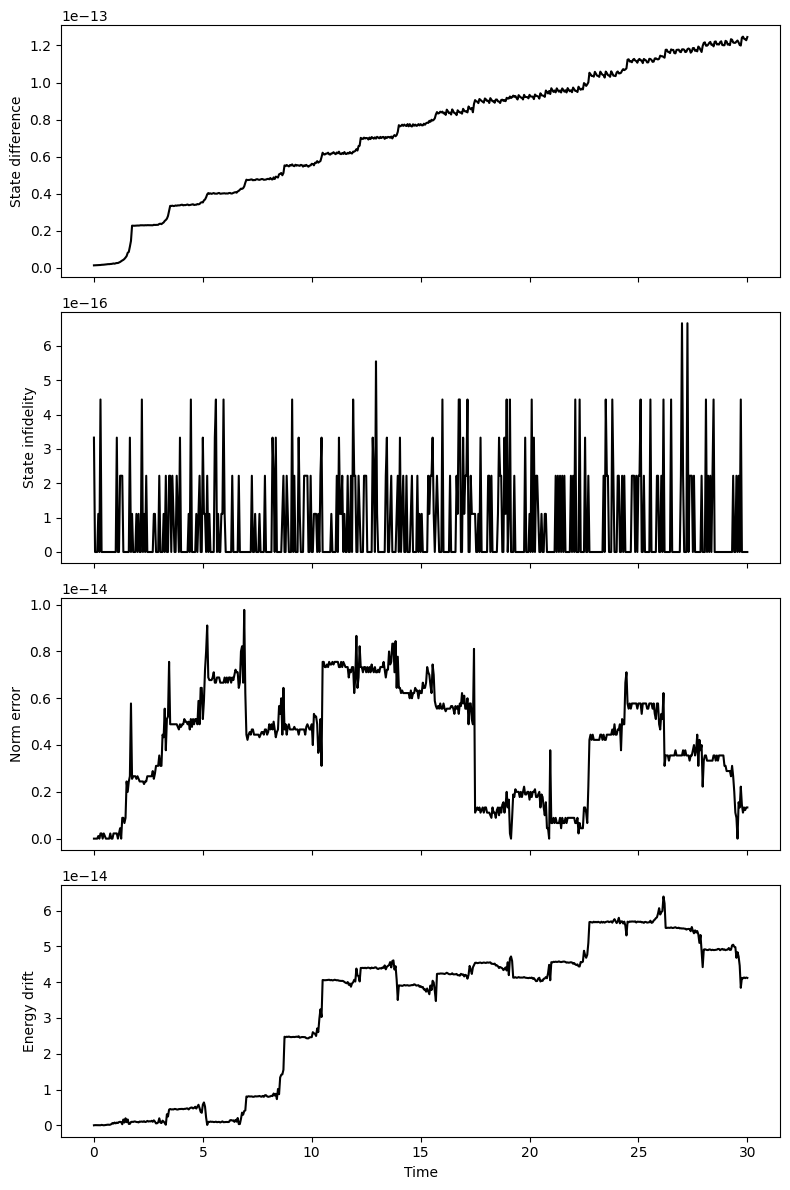

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True)

axes[0].plot(results["times"], results["state_differences"], color="black")
axes[0].set_ylabel("State difference")

axes[1].plot(results["times"], results["infidelities"], color="black")
axes[1].set_ylabel("State infidelity")

axes[2].plot(results["times"], results["norm_errors"], color="black")
axes[2].set_ylabel("Norm error")

axes[3].plot(results["times"], results["energy_errors"], color="black")
axes[3].set_ylabel("Energy drift")
axes[3].set_xlabel("Time")

plt.tight_layout()
plt.show()


In [7]:
results = benchmark_revivals(H, initial_index, initial_time_step=0.05, refinements=4, tolerance=1e-3)

Time step: 0.05000000
Revival score: 0.83671643
Optimal period: 4.75

Time step: 0.02500000
Revival score: 0.83730579
Optimal period: 4.775
Score difference: 5.89361949e-04
Period difference: 2.50000000e-02
Score convergence criterion satisfied.

Time step: 0.01250000
Revival score: 0.83888977
Optimal period: 4.7625
Score difference: 1.58397804e-03
Period difference: 1.25000000e-02

Time step: 0.00625000
Revival score: 0.83888977
Optimal period: 4.7625
Score difference: 0.00000000e+00
Period difference: 0.00000000e+00
Score convergence criterion satisfied.



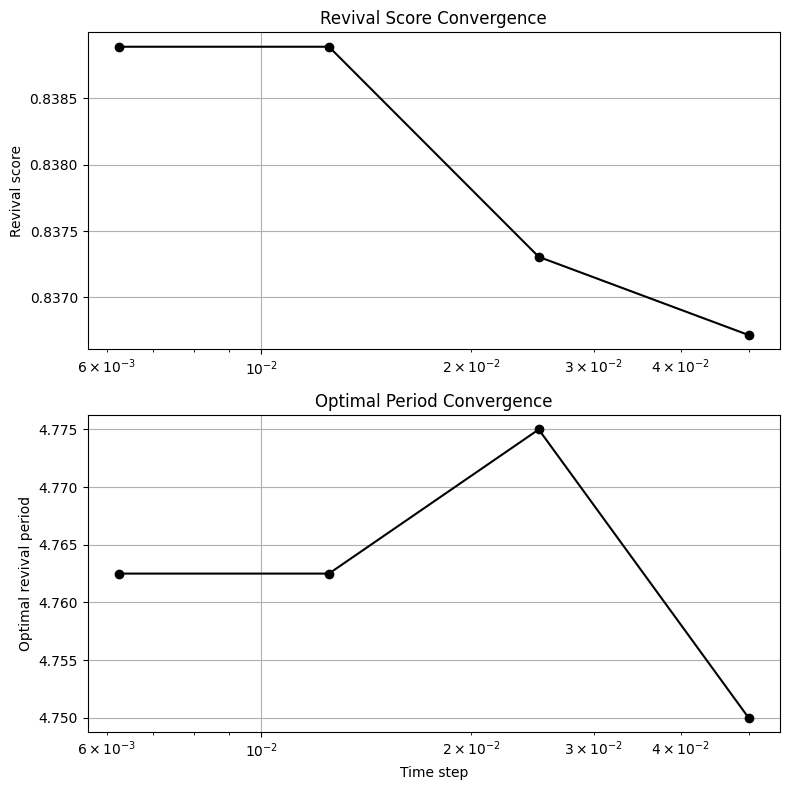

In [ ]:
time_steps = []
revival_scores = []
optimal_periods = []

for result in results:
    time_steps.append(result["time_step"])
    revival_scores.append(result["score"])
    optimal_periods.append(result["period"])


fig, axes = plt.subplots(2, 1, figsize=(8, 8))

axes[0].plot(time_steps, revival_scores, marker="o", linestyle="-", color="black")

axes[0].set_ylabel("Revival score")
axes[0].set_title("Revival Score Convergence")
axes[0].grid(True)
axes[0].set_xscale("log")

axes[1].plot(time_steps, optimal_periods, marker="o", linestyle="-", color="black")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Optimal revival period")
axes[1].set_title("Optimal Period Convergence")
axes[1].grid(True)
axes[1].set_xscale("log")

plt.tight_layout()
plt.show()